# Modelling: Predicting Wins

Goal: predict `win` for a (player, match) row using match-level stats (`player_matches.csv`) and ladder-level player stats (`top300_players.csv`).

This notebook covers:
1. Setup, loading, and cleaning (reused from `02_eda.ipynb`).
2. Visualising feature distributions against the binary `win` target.
3. Fitting and regularizing a **Logistic Regression** model using Stratified 5-Fold Cross Validation via `GridSearchCV` to optimize $\lambda$ ($C = 1/\lambda$).
4. Fitting and tuning non-linear tree models (**Random Forest** and **XGBoost**) using all features via Stratified 5-Fold CV.
5. Evaluating out-of-fold Accuracy, Precision, Recall, and ROC-AUC averaged across the folds, determining the best model by AUC, and plotting feature importances / coefficients.

## Setup

In [1]:
%%capture
# pip install -r requirements.txt

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import requests

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/
from src.config import PROCESSED_DIR

pd.set_option("display.max_columns", None)

WIN_COLOR = "#0AC8B9"   # teal used in 02_eda
LOSS_COLOR = "#C8AA6E"  # gold used in 02_eda

PLAYER_FEATURES = ["games", "win_rate", "leaguePoints"]
MATCH_NUMERIC_FEATURES = [
    "kd_ratio", "totalMinionsKilled", "turretKills", "gold_per_min", "cs_per_min",
    "totalDamageDealtToChampions", "visionScore", "champLevel", "timeCCingOthers",
    "damageDealtToObjectives",
]
MATCH_CATEGORICAL_FEATURES = ["primary_class", "firstBloodKill"]
MATCH_FEATURES = MATCH_NUMERIC_FEATURES + MATCH_CATEGORICAL_FEATURES
TARGET = "win"

## Load Data
Both CSVs were saved with the pandas index as the first column, so `index_col=0` drops it back into the index.

In [3]:
players = pd.read_csv(PROCESSED_DIR / "top300_players.csv", index_col=0)
matches = pd.read_csv(
    PROCESSED_DIR / "player_matches.csv",
    index_col=0,
    parse_dates=["gameCreation"],
    dtype={"patch": str},  # keep e.g. "16.10" from becoming 16.1
)

print(f"players: {players.shape} | matches: {matches.shape}")

players: (300, 14) | matches: (30000, 33)


## Champion Classes
Class tags come from Data Dragon (Riot's static data site). The first tag is the main class.

In [4]:
DDRAGON = "https://ddragon.leagueoflegends.com"
version = requests.get(f"{DDRAGON}/api/versions.json", timeout=10).json()[0]  # latest patch
champs = requests.get(f"{DDRAGON}/cdn/{version}/data/en_US/champion.json", timeout=10).json()["data"]
champ_classes = pd.DataFrame([
    {"champ_key": key.lower(),
     "primary_class": c["tags"][0]}
    for key, c in champs.items()
])
# Match on lowercase names: match-v5 says "FiddleSticks", Data Dragon says "Fiddlesticks"
matches["champ_key"] = matches["championName"].str.lower()
matches = matches.merge(champ_classes, on="champ_key", how="left").drop(columns="champ_key")
print(f"Data Dragon {version} | unmapped champions: {matches.loc[matches.primary_class.isna(), 'championName'].unique()}")
matches["primary_class"].value_counts()

Data Dragon 16.20.1 | unmapped champions: []


primary_class
Fighter     7928
Mage        6986
Marksman    5751
Assassin    4016
Tank        2991
Support     2328
Name: count, dtype: int64

## Clean Data
1. Remove remakes (as in `02_eda`; the only nulls in the raw matches table were in remakes).
2. Compute `kd_ratio = kills / deaths`. For games with 0 deaths, we assign `kills + assists` as the proxy ratio.
3. Remove any remaining nulls in the columns we're using.

In [5]:
# 1. Remove remakes
n_start = len(matches)
matches = matches[matches["is_remake"] == False].copy()
print(f"Removed {n_start - len(matches)} remakes ({(n_start - len(matches)) / n_start:.1%}) -> {len(matches):,} games remain")

# 2. kd_ratio = kills / deaths; with 0 deaths, assign kills + assists
matches["kd_ratio"] = (matches["kills"] / matches["deaths"]).where(
    matches["deaths"] > 0, matches["kills"] + matches["assists"]
)

# 3. Remove nulls in the columns we use
match_cols = MATCH_FEATURES + [TARGET]
null_counts = matches[match_cols].isna().sum()
print("Nulls per column in matches:")
print(null_counts[null_counts > 0].to_string() or "none")

zero_death = matches[matches["deaths"] == 0]
print(f"\n{len(zero_death):,} games have 0 deaths, so kd_ratio was assigned kills + assists. "
      f"Win rate in those games: {zero_death[TARGET].mean():.1%} vs {matches[TARGET].mean():.1%} overall")

matches = matches.dropna(subset=match_cols)
players = players.dropna(subset=PLAYER_FEATURES)
print(f"\nplayers: {players.shape} | matches: {matches.shape}")

Removed 281 remakes (0.9%) -> 29,719 games remain
Nulls per column in matches:
Series([], )

1,119 games have 0 deaths, so kd_ratio was assigned kills + assists. Win rate in those games: 95.8% vs 54.9% overall

players: (300, 14) | matches: (29719, 35)


## Combine Players and Matches
Attach each player's ladder-level features (`games`, `win_rate`, `leaguePoints`) to every one of their matches via `puuid`. This is the combined table.

In [6]:
model_df = matches.merge(players[["puuid"] + PLAYER_FEATURES], on="puuid", how="inner")
print(f"matches rows: {len(matches):,} -> after merge: {len(model_df):,} | players represented: {model_df['puuid'].nunique()}")
model_df[[TARGET] + PLAYER_FEATURES + MATCH_FEATURES].head()

matches rows: 29,719 -> after merge: 29,719 | players represented: 300


,win,games,win_rate,leaguePoints,kd_ratio,totalMinionsKilled,turretKills,gold_per_min,cs_per_min,totalDamageDealtToChampions,visionScore,champLevel,timeCCingOthers,damageDealtToObjectives,primary_class,firstBloodKill
0,False,603,0.593698,4041,0.750000,163,0,384.738806,9.123134,7993,18,12,3,1773,Assassin,False
1,False,603,0.593698,4041,0.555556,32,0,311.000508,0.975114,14722,118,13,33,821,Support,False
2,True,603,0.593698,4041,0.400000,218,0,430.303887,9.243816,15105,23,15,32,4909,Mage,False
3,False,603,0.593698,4041,0.714286,267,1,411.638831,8.361169,26669,59,16,25,5570,Mage,False
4,True,603,0.593698,4041,6.333333,232,3,629.218055,9.001907,30399,23,17,4,15322,Assassin,True


## Visualising Features vs `win`
For each feature, wins and losses are overlaid on the same axes as histograms with KDE curves, showing where the two distributions separate.

Each group is normalised separately (`stat="density"`, `common_norm=False`), so the y-axis shows relative density within that outcome.

In [7]:
OUTCOME_ORDER = ["Win", "Loss"]
OUTCOME_PALETTE = {"Win": WIN_COLOR, "Loss": LOSS_COLOR}


def make_grid(n_plots, n_cols=3, height=3.6):
    """Create a grid of axes with room for n_plots; unused axes are hidden."""
    n_rows = -(-n_plots // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, height * n_rows))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes[n_plots:]:
        ax.set_visible(False)
    return fig, axes


def with_outcome(df):
    """Copy of df with a readable 'outcome' column (Win / Loss) for use as the plot hue."""
    out = df.copy()
    out["outcome"] = out[TARGET].map({True: "Win", False: "Loss"})
    return out


def style_axis(ax, feat, ylabel):
    """Apply shared title / label / grid styling."""
    ax.set_title(feat, loc="left", fontweight="bold")
    ax.set_xlabel(feat)
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.spines[["top", "right"]].set_visible(False)


def plot_numeric_hist_kde(df, features, title, x_cap_quantile=0.995, max_discrete_levels=25):
    """Overlay win vs loss histograms + KDE for each numeric feature (x-axis capped at a high quantile)."""
    df = with_outcome(df)
    fig, axes = make_grid(len(features))
    for i, (ax, feat) in enumerate(zip(axes, features)):
        data = df[df[feat] <= df[feat].quantile(x_cap_quantile)]
        is_discrete = pd.api.types.is_integer_dtype(df[feat]) and df[feat].nunique() <= max_discrete_levels
        sns.histplot(
            data=data, x=feat, hue="outcome", hue_order=OUTCOME_ORDER, palette=OUTCOME_PALETTE,
            kde=True, stat="density", common_norm=False, discrete=is_discrete,
            alpha=0.4, edgecolor="white", linewidth=0.3, line_kws={"linewidth": 2},
            legend=(i == 0), ax=ax,
        )
        style_axis(ax, feat, "Density")
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_categorical_hist(df, features, title):
    """Side-by-side win vs loss bars per level (proportion of each outcome's games)."""
    df = with_outcome(df)
    fig, axes = make_grid(len(features))
    for i, (ax, feat) in enumerate(zip(axes, features)):
        levels = [str(lvl) for lvl in sorted(df[feat].unique())]
        data = df.assign(**{feat: pd.Categorical(df[feat].astype(str), categories=levels)})
        sns.histplot(
            data=data, x=feat, hue="outcome", hue_order=OUTCOME_ORDER, palette=OUTCOME_PALETTE,
            multiple="dodge", shrink=0.8, stat="proportion", common_norm=False,
            alpha=0.8, legend=(i == 0), ax=ax,
        )
        ax.tick_params(axis="x", rotation=30 if len(levels) > 2 else 0)
        style_axis(ax, feat, "Proportion of games")
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

### Players dataset: `games`, `win_rate`, `leaguePoints`
These are season-long ladder stats, so every match by the same player shares the same value.

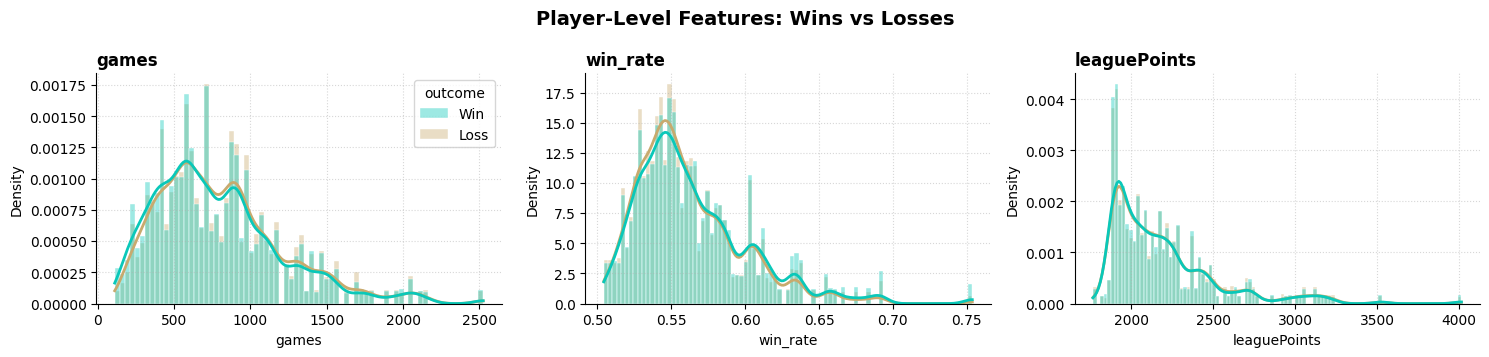

In [8]:
plot_numeric_hist_kde(model_df, PLAYER_FEATURES, "Player-Level Features: Wins vs Losses")

### Matches dataset: numeric features
The x-axis of each plot is capped at the 99.5th percentile so extreme games don't compress the distribution.

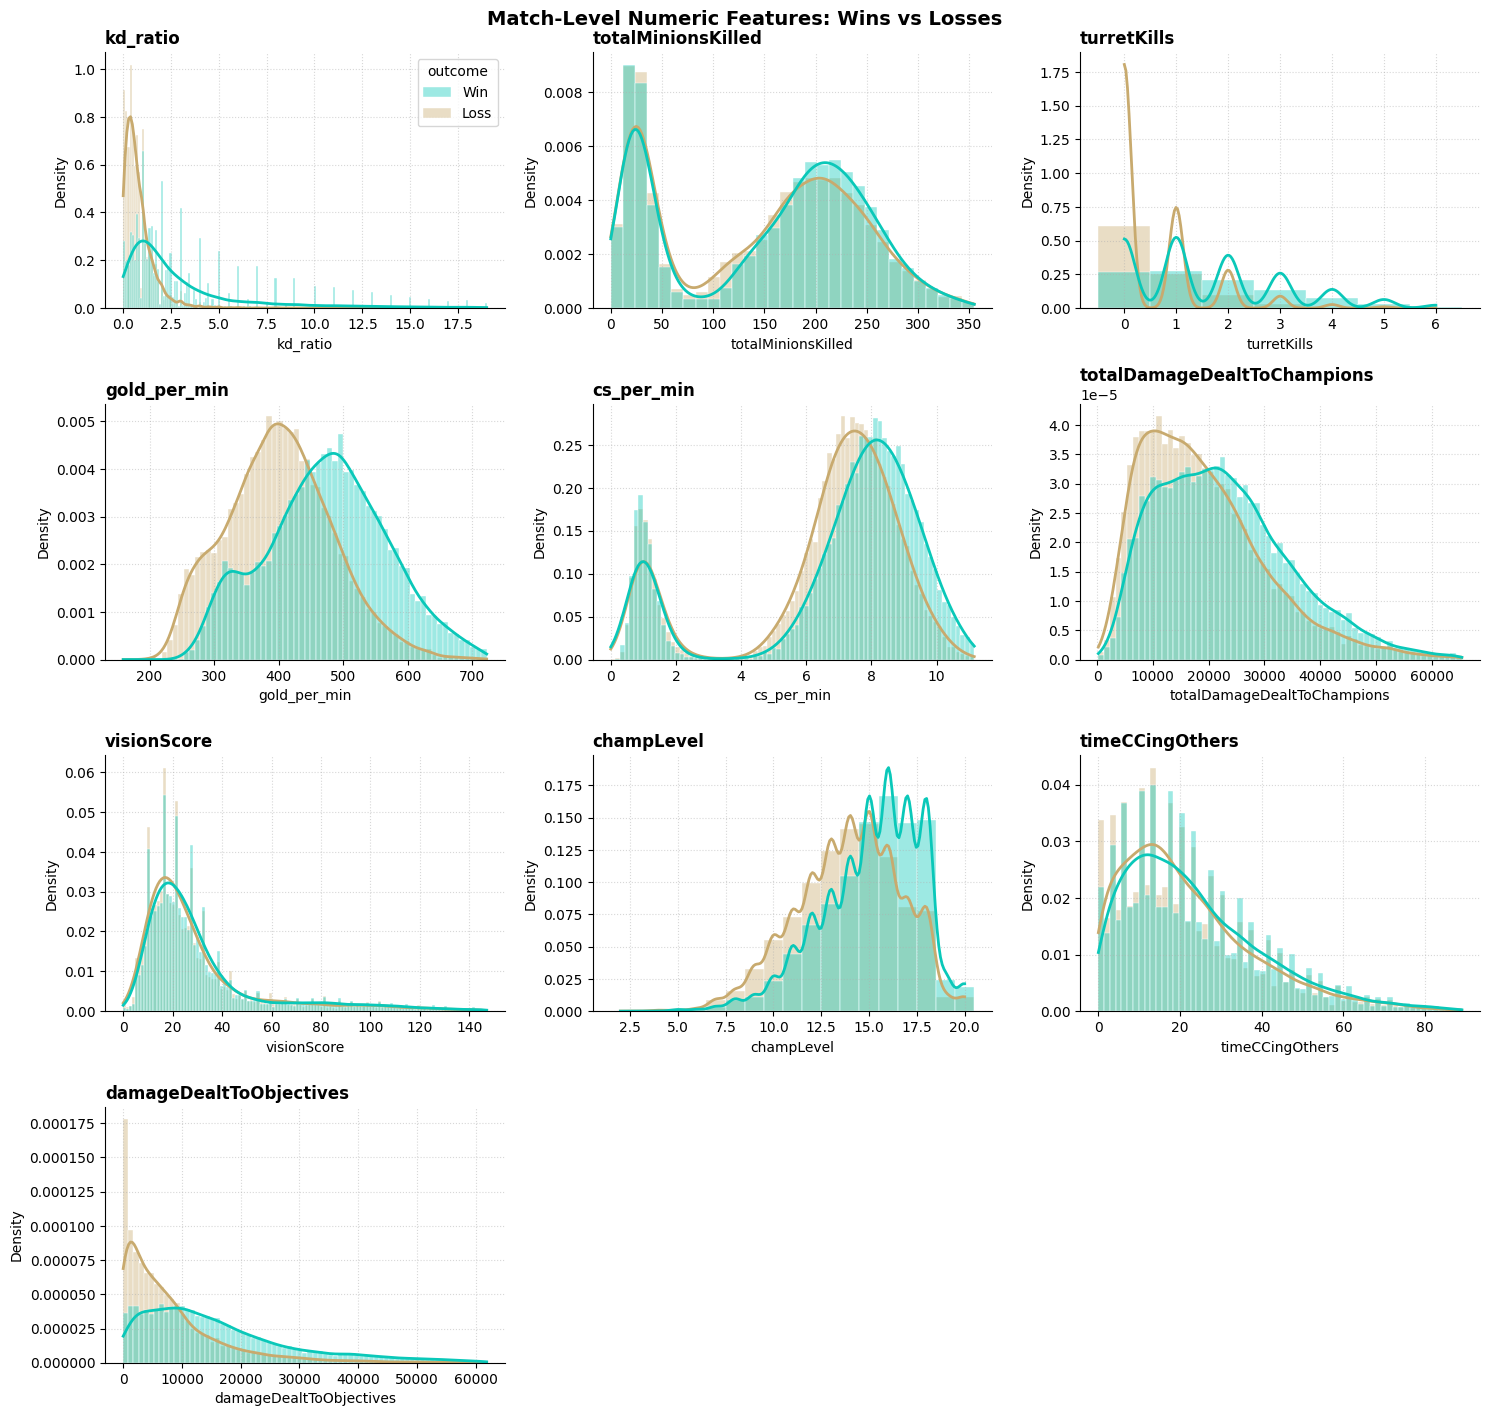

In [9]:
plot_numeric_hist_kde(model_df, MATCH_NUMERIC_FEATURES, "Match-Level Numeric Features: Wins vs Losses")

### Matches dataset: categorical features
`primary_class` and `firstBloodKill` have discrete levels on the x-axis, shown with side-by-side bars.

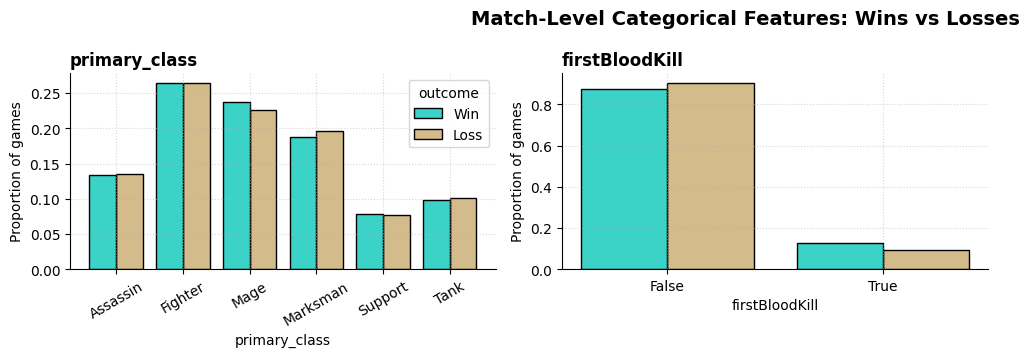

In [10]:
plot_categorical_hist(model_df, MATCH_CATEGORICAL_FEATURES, "Match-Level Categorical Features: Wins vs Losses")

## 1. Logistic Regression Modelling

We fit an L2-regularized logistic regression model using all 12 match features (`MATCH_FEATURES` = 10 numeric features + `primary_class` one-hot encoded + `firstBloodKill`).

### Cross-Validation & Metric Selection
In penalized logistic regression, the cost function minimizes:
$$\text{Loss}(w) + \lambda \|w\|_2^2$$
In `scikit-learn`'s `LogisticRegression`, the regularization strength is parameterized by $C = \frac{1}{\lambda}$. Thus, smaller $C$ means stronger regularization (larger $\lambda$), and larger $C$ means weaker regularization (smaller $\lambda$).

We use **Stratified 5-Fold Cross Validation** via `GridSearchCV` across a grid of $\lambda$ values to find the optimal $\lambda^*$ that maximizes the out-of-fold **ROC-AUC** on the predicted probabilities $\hat{p} = P(\text{win}=1)$, properly preserving class proportions across folds given target class imbalance. We also evaluate **Accuracy**, **Precision**, and **Recall** (at threshold 0.5) averaged across the 5 validation folds.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve

# Feature set and target
LR_FEATURES = MATCH_FEATURES
X_lr = matches[LR_FEATURES]
y = matches[TARGET].astype(int)

# Preprocessor: scale numeric columns, one-hot encode primary_class, passthrough binary firstBloodKill
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), MATCH_NUMERIC_FEATURES),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), ["primary_class"]),
        ("bin", "passthrough", ["firstBloodKill"]),
    ]
)

# Grid of lambda values (C = 1 / lambda)
lambdas = np.logspace(-4, 3, 22)


def cv_evaluate_classifier(X, y, preprocessor, clf, param_grid, n_splits=5, random_state=42):
    """
    Fits and tunes a classifier pipeline using GridSearchCV with StratifiedKFold
    cross-validation to address class imbalance.
    
    Computes Accuracy, Precision, Recall, and ROC-AUC across folds,
    as well as out-of-fold predicted probabilities for the optimal model.
    """
    pipe = Pipeline([
        ("prep", preprocessor),
        ("clf", clf),
    ])
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scoring = {
        "roc_auc": "roc_auc",
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
    }
    grid = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv,
        scoring=scoring,
        refit="roc_auc",
    )
    grid.fit(X, y)

    # Compute out-of-fold predicted probabilities for the optimal model
    oof_preds = cross_val_predict(
        grid.best_estimator_, X, y, cv=cv, method="predict_proba"
    )[:, 1]

    # Package fold-level and summary metrics
    cv_res = grid.cv_results_
    records = []
    for i in range(len(cv_res["params"])):
        rec = {
            "params": cv_res["params"][i],
            "mean_auc": cv_res["mean_test_roc_auc"][i],
            "std_auc": cv_res["std_test_roc_auc"][i],
            "mean_acc": cv_res["mean_test_accuracy"][i],
            "std_acc": cv_res["std_test_accuracy"][i],
            "mean_prec": cv_res["mean_test_precision"][i],
            "std_prec": cv_res["std_test_precision"][i],
            "mean_rec": cv_res["mean_test_recall"][i],
            "std_rec": cv_res["std_test_recall"][i],
            "fold_aucs": [cv_res[f"split{k}_test_roc_auc"][i] for k in range(n_splits)],
            "fold_accs": [cv_res[f"split{k}_test_accuracy"][i] for k in range(n_splits)],
            "fold_precs": [cv_res[f"split{k}_test_precision"][i] for k in range(n_splits)],
            "fold_recs": [cv_res[f"split{k}_test_recall"][i] for k in range(n_splits)],
        }
        for param_name, param_val in cv_res["params"][i].items():
            clean_name = param_name.replace("clf__", "")
            rec[clean_name] = param_val
            if clean_name == "max_depth":
                rec["max_depth"] = str(param_val)
            elif clean_name == "C":
                rec["lambda"] = 1.0 / param_val if param_val != 0 else np.inf
        records.append(rec)

    results_df = pd.DataFrame(records)
    best_row = results_df.iloc[grid.best_index_].copy()
    return results_df, best_row, oof_preds

### Logistic Regression CV Results & Tuning Curve

=== Logistic Regression CV Results ===
Optimal Lambda:   1.000000  (C = 1.0000)
Fold AUCs:        [np.float64(0.8735), np.float64(0.8744), np.float64(0.877), np.float64(0.8792), np.float64(0.8651)]
Average ROC-AUC:  0.8738 ± 0.0048
Average Accuracy: 79.46% ± 0.73%
Average Precision:82.51% ± 0.65%
Average Recall:   79.44% ± 0.77%


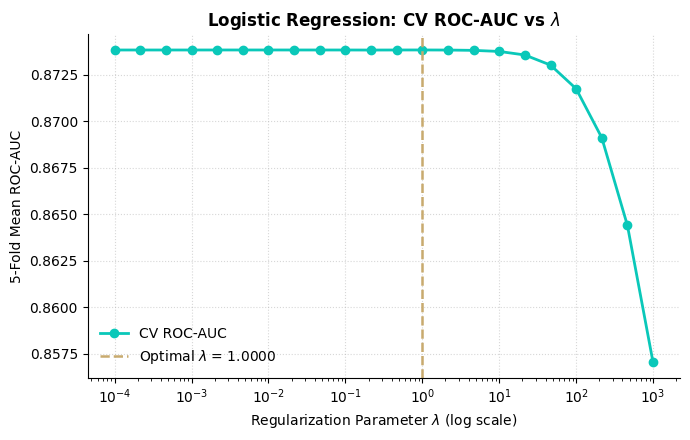

In [12]:
lr_results, lr_best, oof_lr = cv_evaluate_classifier(
    X_lr, y, preprocessor_lr,
    LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000, random_state=42),
    {"clf__C": [1.0 / lam for lam in lambdas]},
)

print("=== Logistic Regression CV Results ===")
print(f"Optimal Lambda:   {lr_best['lambda']:.6f}  (C = {lr_best['C']:.4f})")
print(f"Fold AUCs:        {[round(a, 4) for a in lr_best['fold_aucs']]}")
print(f"Average ROC-AUC:  {lr_best['mean_auc']:.4f} ± {lr_best['std_auc']:.4f}")
print(f"Average Accuracy: {lr_best['mean_acc']:.2%} ± {lr_best['std_acc']:.2%}")
print(f"Average Precision:{lr_best['mean_prec']:.2%} ± {lr_best['std_prec']:.2%}")
print(f"Average Recall:   {lr_best['mean_rec']:.2%} ± {lr_best['std_rec']:.2%}")

# Plot CV Tuning Curve for Logistic Regression
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(lr_results["lambda"], lr_results["mean_auc"], marker="o", color=WIN_COLOR, linewidth=2, label="CV ROC-AUC")
ax.axvline(lr_best["lambda"], color=LOSS_COLOR, linestyle="--", linewidth=1.8, label=f"Optimal $\lambda$ = {lr_best['lambda']:.4f}")
ax.set_xscale("log")
ax.set_title("Logistic Regression: CV ROC-AUC vs $\lambda$", fontweight="bold")
ax.set_xlabel("Regularization Parameter $\lambda$ (log scale)")
ax.set_ylabel("5-Fold Mean ROC-AUC")
ax.legend(frameon=False)
ax.grid(True, linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Logistic Regression Coefficients
We fit the logistic model with optimal $\lambda^*$ on the full dataset to inspect the learned coefficients (standardized log-odds weights).

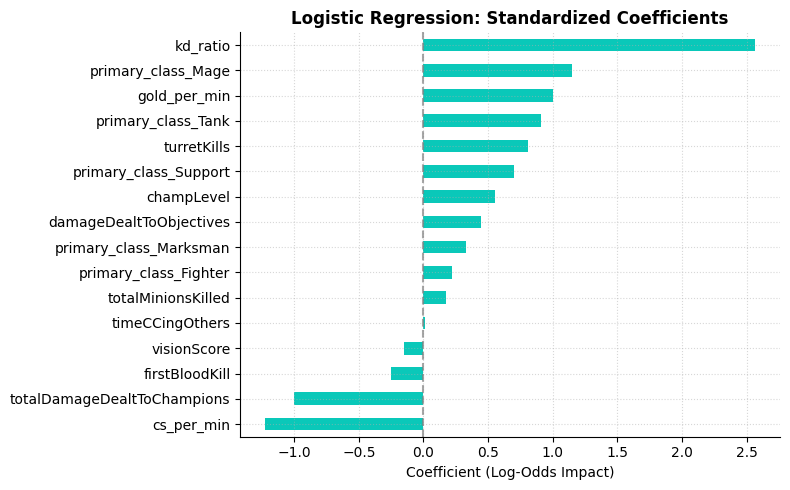

In [13]:
# Fit Logistic Regression with optimal C
final_pipe_lr = Pipeline([
    ("prep", preprocessor_lr),
    ("clf", LogisticRegression(C=lr_best["C"], penalty="l2", solver="lbfgs", max_iter=1000, random_state=42)),
])
final_pipe_lr.fit(X_lr, y)

# Extract feature names from preprocessor
ohe_names = final_pipe_lr.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(["primary_class"])
lr_feature_names = MATCH_NUMERIC_FEATURES + list(ohe_names) + ["firstBloodKill"]
lr_coefs = pd.Series(final_pipe_lr.named_steps["clf"].coef_[0], index=lr_feature_names).sort_values()

# Plot coefficients
fig, ax = plt.subplots(figsize=(8, 5))
lr_coefs.plot(kind="barh", ax=ax, color=WIN_COLOR)
ax.set_title("Logistic Regression: Standardized Coefficients", fontweight="bold")
ax.axvline(0, color="gray", linestyle="--", alpha=0.7)
ax.set_xlabel("Coefficient (Log-Odds Impact)")
ax.grid(True, linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Tree-Based Models: Random Forest & XGBoost

We now apply the same 5-fold cross-validation procedure to two non-linear tree-based ensemble models, using **all features** from both the matches and players datasets:
- 10 match numeric features (`kd_ratio`, `turretKills`, `gold_per_min`, `totalDamageDealtToChampions`, `damageDealtToObjectives`, etc.)
- 3 player ladder features (`games`, `win_rate`, `leaguePoints`)
- `firstBloodKill` (binary)
- `primary_class` (one-hot encoded)

We evaluate each model using **5-Fold Stratified CV** with `GridSearchCV` (via `cv_evaluate_classifier`), optimize tree complexity by **ROC-AUC**, and plot the resulting **feature importances** for both models.

In [14]:
from sklearn.ensemble import RandomForestClassifier
try:
    from xgboost import XGBClassifier
except ImportError:
    raise ImportError("xgboost is not installed. Please run `!pip install xgboost` in your environment to use XGBClassifier.")

# All features across matches and players tables
ALL_NUMERIC_FEATURES = MATCH_NUMERIC_FEATURES + PLAYER_FEATURES
ALL_CATEGORICAL_FEATURES = ["primary_class"]
ALL_BINARY_FEATURES = ["firstBloodKill"]
ALL_FEATURES = ALL_NUMERIC_FEATURES + ALL_CATEGORICAL_FEATURES + ALL_BINARY_FEATURES

# Extract data from model_df
X_tree = model_df[ALL_FEATURES]
y_tree = model_df[TARGET].astype(int)

# Preprocessor for tree models (one-hot encodes primary_class, leaves numerics unscaled)
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", ALL_NUMERIC_FEATURES),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), ALL_CATEGORICAL_FEATURES),
        ("bin", "passthrough", ALL_BINARY_FEATURES),
    ]
)

### Random Forest Model
We tune the tree depth `max_depth` across 5-Fold Stratified Cross Validation using `GridSearchCV` to find the optimal configuration that maximizes ROC-AUC.

In [15]:
rf_depth_grid = [6, 10, 14, 18, None]

print("Evaluating Random Forest across max_depth grid using 5-Fold Stratified CV with GridSearchCV...")
rf_results_df, rf_best, oof_rf = cv_evaluate_classifier(
    X_tree, y_tree, tree_preprocessor,
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    {"clf__max_depth": rf_depth_grid},
)

print("\n=== Random Forest CV Results ===")
print(f"Optimal max_depth: {rf_best['max_depth']}")
print(f"Fold AUCs:         {[round(a, 4) for a in rf_best['fold_aucs']]}")
print(f"Average ROC-AUC:   {rf_best['mean_auc']:.4f} ± {rf_best['std_auc']:.4f}")
print(f"Average Accuracy:  {rf_best['mean_acc']:.2%} ± {rf_best['std_acc']:.2%}")
print(f"Average Precision: {rf_best['mean_prec']:.2%} ± {rf_best['std_prec']:.2%}")
print(f"Average Recall:    {rf_best['mean_rec']:.2%} ± {rf_best['std_rec']:.2%}")

Evaluating Random Forest across max_depth grid using 5-Fold Stratified CV with GridSearchCV...



=== Random Forest CV Results ===
Optimal max_depth: None
Fold AUCs:         [np.float64(0.9011), np.float64(0.903), np.float64(0.9081), np.float64(0.9034), np.float64(0.8955)]
Average ROC-AUC:   0.9022 ± 0.0040
Average Accuracy:  81.85% ± 0.54%
Average Precision: 82.67% ± 0.55%
Average Recall:    84.70% ± 0.64%


### XGBoost Model
We tune the tree depth `max_depth` for XGBoost across 5-Fold Stratified Cross Validation using `GridSearchCV` to find the optimal configuration that maximizes ROC-AUC.

In [16]:
xgb_depth_grid = [3, 5, 7, 9]

print("Evaluating XGBoost across max_depth grid using 5-Fold Stratified CV with GridSearchCV...")
xgb_results_df, xgb_best, oof_xgb = cv_evaluate_classifier(
    X_tree, y_tree, tree_preprocessor,
    XGBClassifier(
        n_estimators=100, learning_rate=0.08,
        tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=-1
    ),
    {"clf__max_depth": xgb_depth_grid},
)

print("\n=== XGBoost CV Results ===")
print(f"Optimal max_depth: {xgb_best['max_depth']}")
print(f"Fold AUCs:         {[round(a, 4) for a in xgb_best['fold_aucs']]}")
print(f"Average ROC-AUC:   {xgb_best['mean_auc']:.4f} ± {xgb_best['std_auc']:.4f}")
print(f"Average Accuracy:  {xgb_best['mean_acc']:.2%} ± {xgb_best['std_acc']:.2%}")
print(f"Average Precision: {xgb_best['mean_prec']:.2%} ± {xgb_best['std_prec']:.2%}")
print(f"Average Recall:    {xgb_best['mean_rec']:.2%} ± {xgb_best['std_rec']:.2%}")

Evaluating XGBoost across max_depth grid using 5-Fold Stratified CV with GridSearchCV...



=== XGBoost CV Results ===
Optimal max_depth: 9
Fold AUCs:         [np.float64(0.9103), np.float64(0.9115), np.float64(0.9146), np.float64(0.9147), np.float64(0.9065)]
Average ROC-AUC:   0.9115 ± 0.0030
Average Accuracy:  82.84% ± 0.55%
Average Precision: 83.61% ± 0.63%
Average Recall:    85.49% ± 0.55%


### Grand Model Comparison: Logistic Regression vs Random Forest vs XGBoost
We compare all three models side-by-side on their 5-fold cross-validation performance, plot their out-of-fold ROC curves, and declare the overall winner by AUC.

,Model,Hyperparameters,CV ROC-AUC (mean ± std),CV Accuracy,CV Precision,CV Recall
0,Logistic Regression,Optimal Lambda=1.0000 (C=1.0000),0.8738 ± 0.0048,79.46%,82.51%,79.44%
1,Random Forest,max_depth=None,0.9022 ± 0.0040,81.85%,82.67%,84.70%
2,XGBoost,max_depth=9,0.9115 ± 0.0030,82.84%,83.61%,85.49%



🏆 Overall Best Model determined by AUC: XGBoost (ROC-AUC = 0.9115)


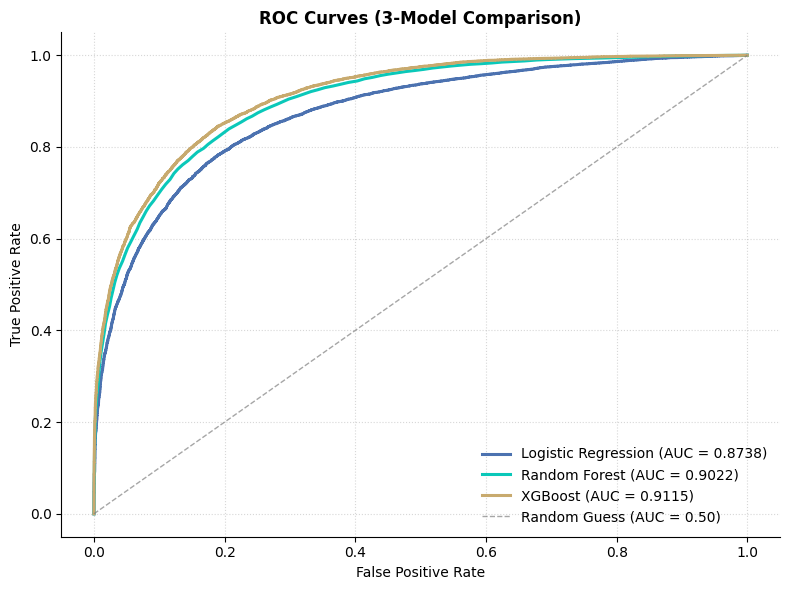

In [17]:
# Grand Comparison Table
grand_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Hyperparameters": f"Optimal Lambda={lr_best['lambda']:.4f} (C={lr_best['C']:.4f})",
        "CV ROC-AUC (mean ± std)": f"{lr_best['mean_auc']:.4f} ± {lr_best['std_auc']:.4f}",
        "CV Accuracy": f"{lr_best['mean_acc']:.2%}",
        "CV Precision": f"{lr_best['mean_prec']:.2%}",
        "CV Recall": f"{lr_best['mean_rec']:.2%}",
    },
    {
        "Model": "Random Forest",
        "Hyperparameters": f"max_depth={rf_best['max_depth']}",
        "CV ROC-AUC (mean ± std)": f"{rf_best['mean_auc']:.4f} ± {rf_best['std_auc']:.4f}",
        "CV Accuracy": f"{rf_best['mean_acc']:.2%}",
        "CV Precision": f"{rf_best['mean_prec']:.2%}",
        "CV Recall": f"{rf_best['mean_rec']:.2%}",
    },
    {
        "Model": "XGBoost",
        "Hyperparameters": f"max_depth={xgb_best['max_depth']}",
        "CV ROC-AUC (mean ± std)": f"{xgb_best['mean_auc']:.4f} ± {xgb_best['std_auc']:.4f}",
        "CV Accuracy": f"{xgb_best['mean_acc']:.2%}",
        "CV Precision": f"{xgb_best['mean_prec']:.2%}",
        "CV Recall": f"{xgb_best['mean_rec']:.2%}",
    },
])
display(grand_comparison)

# Determine overall winner by AUC
auc_map = {
    "Logistic Regression": lr_best["mean_auc"],
    "Random Forest": rf_best["mean_auc"],
    "XGBoost": xgb_best["mean_auc"],
}
best_overall_model = max(auc_map, key=auc_map.get)
print(f"\n🏆 Overall Best Model determined by AUC: {best_overall_model} (ROC-AUC = {auc_map[best_overall_model]:.4f})")

# Optimal depth parameters for final fits and plotting
rf_opt_d = None if str(rf_best["max_depth"]) == "None" else int(rf_best["max_depth"])
xgb_opt_d = int(xgb_best["max_depth"])

# Compute ROC curves from out-of-fold predictions obtained during CV
fpr_lr, tpr_lr, _ = roc_curve(y, oof_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_tree, oof_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_tree, oof_xgb)

# Plot ROC Curves for all 3 models
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_lr, tpr_lr, color="#4C72B0", linewidth=2.2, label=f"Logistic Regression (AUC = {lr_best['mean_auc']:.4f})")
ax.plot(fpr_rf, tpr_rf, color=WIN_COLOR, linewidth=2.2, label=f"Random Forest (AUC = {rf_best['mean_auc']:.4f})")
ax.plot(fpr_xgb, tpr_xgb, color=LOSS_COLOR, linewidth=2.2, label=f"XGBoost (AUC = {xgb_best['mean_auc']:.4f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, alpha=0.7, label="Random Guess (AUC = 0.50)")
ax.set_title("ROC Curves (3-Model Comparison)", fontweight="bold")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend(frameon=False, loc="lower right")
ax.grid(True, linestyle=":", alpha=0.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Feature Importance: Random Forest & XGBoost
We fit both tree models on the entire dataset using their optimal hyperparameters and plot their relative feature importances side-by-side.

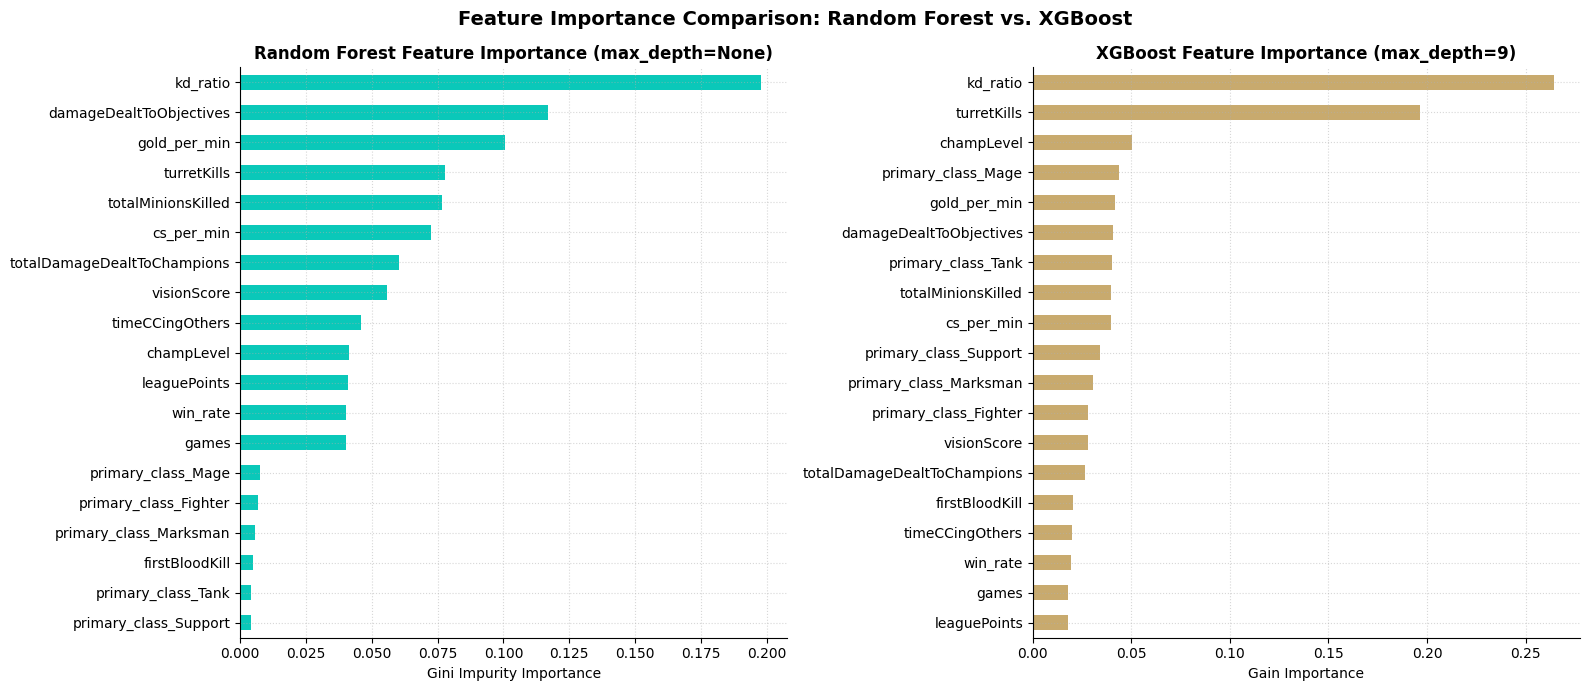

In [18]:
# 1. Fit final Random Forest model
final_pipe_rf = Pipeline([
    ("prep", tree_preprocessor),
    ("clf", RandomForestClassifier(n_estimators=100, max_depth=rf_opt_d, random_state=42, n_jobs=-1)),
])
final_pipe_rf.fit(X_tree, y_tree)

# 2. Fit final XGBoost model
final_pipe_xgb = Pipeline([
    ("prep", tree_preprocessor),
    ("clf", XGBClassifier(
        n_estimators=100, max_depth=xgb_opt_d, learning_rate=0.08,
        tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=-1
    )),
])
final_pipe_xgb.fit(X_tree, y_tree)

# Extract transformed feature names
ohe_tree_names = final_pipe_rf.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(ALL_CATEGORICAL_FEATURES)
all_tree_feature_names = ALL_NUMERIC_FEATURES + list(ohe_tree_names) + ALL_BINARY_FEATURES

# Extract and sort importances
rf_importances = pd.Series(final_pipe_rf.named_steps["clf"].feature_importances_, index=all_tree_feature_names).sort_values()
xgb_importances = pd.Series(final_pipe_xgb.named_steps["clf"].feature_importances_, index=all_tree_feature_names).sort_values()

# Plot Feature Importances Side-by-Side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

rf_importances.plot(kind="barh", ax=ax1, color=WIN_COLOR)
ax1.set_title(f"Random Forest Feature Importance (max_depth={rf_best['max_depth']})", fontweight="bold")
ax1.set_xlabel("Gini Impurity Importance")
ax1.grid(True, linestyle=":", alpha=0.5)
ax1.spines[["top", "right"]].set_visible(False)

xgb_importances.plot(kind="barh", ax=ax2, color=LOSS_COLOR)
ax2.set_title(f"XGBoost Feature Importance (max_depth={xgb_best['max_depth']})", fontweight="bold")
ax2.set_xlabel("Gain Importance")
ax2.grid(True, linestyle=":", alpha=0.5)
ax2.spines[["top", "right"]].set_visible(False)

fig.suptitle("Feature Importance Comparison: Random Forest vs. XGBoost", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()